<a href="https://colab.research.google.com/github/Brant-c/chess-opening-ml/blob/main/Milestone3%5Bg66%5D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 3 - Baseline Reproduction
### Group 66: Personalized Chess Opening Recommendations

This notebook trains and evaluates two baseline models using
our cleaned August 2016 Lichess dataset.

**Models**
1. Majority Class (Naive Benchmark)
2. Decision Tree (Course-Level Baseline)

**Target:** Game Result (White Win, Black Win, Draw)

**Primary Metric:** Macro F1-Score

**Data Split:** 80% Training / 15% Validation / 5% Testing

In [36]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

## 1. Dataset

We use the cleaned August 2016 Lichess Standard Rated Games
dataset exported from our Milestone 2 EDA notebook.

In [37]:
# Load cleaned dataset from Milestone 2
df = pd.read_parquet("lichess_clean_2016_08.parquet")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (99397, 11)


,Event,Result,WhiteElo,BlackElo,ECO,Opening,TimeControl,Termination,Moves,AverageElo,EloDiff
0,Rated Blitz tournament https://lichess.org/tou...,0-1,1261,1345,B00,"St. George Defense: New St. George, Three Pawn...",300+0,Normal,d2d4 e7e6 c2c4 a7a6 e2e4 c7c5 f1d3 c5d4 g1f3 f...,1303.0,-84
1,Rated Bullet game,0-1,1744,1848,C53,"Italian Game: Classical Variation, Albin Gambit",120+1,Time forfeit,e2e4 e7e5 g1f3 b8c6 f1c4 f8c5 c2c3 g8f6 e1g1 d...,1796.0,-104
2,Rated Bullet tournament https://lichess.org/to...,1-0,1485,1471,E90,King's Indian Defense: Larsen Variation,60+0,Time forfeit,d2d4 g8f6 c2c4 g7g6 b1c3 f8g7 g1f3 d7d6 e2e4 e...,1478.0,14
3,Rated Bullet tournament https://lichess.org/to...,0-1,2107,2132,A46,Torre Attack #2,60+0,Normal,d2d4 g8f6 g1f3 e7e6 g2g3 b7b6 f1g2 c8b7 e1g1 d...,2119.5,-25
4,Rated Blitz tournament https://lichess.org/tou...,1-0,1598,1525,D15,Slav Defense: Three Knights Variation,300+0,Normal,d2d4 d7d5 c2c4 c7c6 b1c3 g8f6 g1f3 c8f5 c1g5 h...,1561.5,73


## 1. Feature Selection

We use four features to predict chess game outcomes:

- AverageElo: Average rating of both players
- EloDiff: White player's rating minus Black player's rating
- ECO: Chess opening classification
- TimeControl: Time settings for the game

Target: Result (White Win, Black Win, Draw)

Full game moves and termination are excluded because they
contain information unavailable before the game ends.

In [38]:
# Select the features and target variable
features = ["AverageElo", "EloDiff", "ECO", "TimeControl"]

X = df[features].copy()
y = df["Result"].copy()

# Check missing values and class distribution
print("Missing values:")
print(X.isnull().sum())

print("\nResults:")
print(y.value_counts())

Missing values:
AverageElo     0
EloDiff        0
ECO            0
TimeControl    0
dtype: int64

Results:
Result
1-0        49413
0-1        46080
1/2-1/2     3904
Name: count, dtype: int64


## 2. Data Splitting

The dataset is split into:
- 80% Training
- 15% Validation
- 5% Testing

The test set will remain untouched during model development.

In [39]:
from sklearn.model_selection import train_test_split

# Split into 80% training and 20% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split remaining 20% into 15% validation and 5% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.25,
    random_state=42,
    stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 79517
Validation: 14910
Testing: 4970


In [40]:
# Check split sizes
total = len(df)

print("Training:", round(len(X_train) / total * 100, 2), "%")
print("Validation:", round(len(X_val) / total * 100, 2), "%")
print("Testing:", round(len(X_test) / total * 100, 2), "%")

# Check class balance
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation class distribution:")
print(y_val.value_counts(normalize=True).round(3))

Training: 80.0 %
Validation: 15.0 %
Testing: 5.0 %

Training class distribution:
Result
1-0        0.497
0-1        0.464
1/2-1/2    0.039
Name: proportion, dtype: float64

Validation class distribution:
Result
1-0        0.497
0-1        0.464
1/2-1/2    0.039
Name: proportion, dtype: float64


## 3. Naive Baseline — Majority Class

The naive model always predicts the most common game result
from the training dataset.

It does not learn relationships between the input features
and results.

In [41]:
# Train majority-class benchmark
naive = DummyClassifier(strategy="most_frequent")
naive.fit(X_train, y_train)

# Predict validation results
naive_preds = naive.predict(X_val)

# Evaluate
naive_accuracy = accuracy_score(y_val, naive_preds)
naive_f1 = f1_score(y_val, naive_preds, average="macro")

print("Naive Accuracy:", round(naive_accuracy, 4))
print("Naive Macro F1:", round(naive_f1, 4))

Naive Accuracy: 0.4971
Naive Macro F1: 0.2214


## 4. Decision Tree Baseline

Decision Tree learns rules from player ratings, chess
openings, and time controls to predict game outcomes.

We use fixed initial settings rather than tuning the model
extensively at this stage.

In [42]:
# Encode categorical features
preprocessor = ColumnTransformer([
    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     ["ECO", "TimeControl"])
], remainder="passthrough")

# Create Decision Tree pipeline
tree = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=50,
        random_state=42
    ))
])

# Train using training data only
tree.fit(X_train, y_train)

# Predict validation outcomes
tree_preds = tree.predict(X_val)

In [43]:
# Evaluate Decision Tree predictions
tree_accuracy = accuracy_score(y_val, tree_preds)
tree_f1 = f1_score(y_val, tree_preds, average="macro")

print("Decision Tree Accuracy:", round(tree_accuracy, 4))
print("Decision Tree Macro F1:", round(tree_f1, 4))

Decision Tree Accuracy: 0.6245
Decision Tree Macro F1: 0.423


## 5. Baseline Comparison

Both models are evaluated using the same validation dataset.

Macro F1 is the primary metric because draws are much
less common than wins.

Accuracy is included as a supporting metric.

In [44]:
results = pd.DataFrame({
    "Model": ["Majority Class", "Decision Tree"],
    "Macro F1": [naive_f1, tree_f1],
    "Accuracy": [naive_accuracy, tree_accuracy]
})

results.round(4)

,Model,Macro F1,Accuracy
0,Majority Class,0.2214,0.4971
1,Decision Tree,0.4230,0.6245


In [45]:
from sklearn.metrics import classification_report

# Show precision, recall, and F1 for each outcome
print(classification_report(
    y_val,
    tree_preds,
    zero_division=0
))

              precision    recall  f1-score   support

         0-1       0.63      0.58      0.61      6912
         1-0       0.62      0.71      0.66      7412
     1/2-1/2       0.00      0.00      0.00       586

    accuracy                           0.62     14910
   macro avg       0.42      0.43      0.42     14910
weighted avg       0.60      0.62      0.61     14910



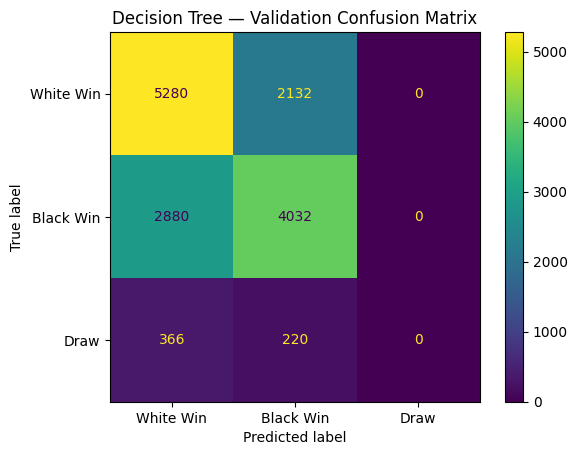

In [46]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Visualize Decision Tree predictions
ConfusionMatrixDisplay.from_predictions(
    y_val,
    tree_preds,
    labels=["1-0", "0-1", "1/2-1/2"],
    display_labels=["White Win", "Black Win", "Draw"]
)

plt.title("Decision Tree — Validation Confusion Matrix")
plt.show()

### Baseline Results and Comparison

The Decision Tree performed noticeably better than the naive majority-class model. Our Macro F1 score increased from **0.2214 to 0.4230**, while accuracy improved from **49.71% to 62.45%**. This could mean that features like player ratings, opening choice, and time control provide useful information when predicting game outcomes.

The classification report and confusion matrix show that the Decision Tree **did not predict any draws correctly**. All 586 draws in the validation set were classified as either a White or Black win. This is likely influenced by the fact that draws only represent around 4% of our dataset, making them difficult for the model to learn compared to wins.

Overall, the Decision Tree is a clear improvement over simply predicting the most common result, but the poor performance on draws is an important limitation. For our next experiments, we should investigate ways to handle this class imbalance and see whether other models can improve our Macro F1 score.